In [1]:
!pip install pyyaml pillow matplotlib \
    --trusted-host pypi.org \
    --trusted-host files.pythonhosted.org

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import ultralytics
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)
print("Installation successful")

Ultralytics version: 8.4.75
Installation successful


In [3]:
from pathlib import Path
from collections import Counter
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
import torch
import zipfile
import yaml
import shutil
import os

BASE_DIR = Path.cwd()

ZIP_PATH = BASE_DIR / "archive.zip"
EXTRACT_DIR = BASE_DIR / "extracted_dataset"
RUNS_DIR = BASE_DIR / "training_runs"

print("Current notebook directory:", BASE_DIR)
print("ZIP path:", ZIP_PATH)
print("ZIP exists:", ZIP_PATH.exists())

Current notebook directory: /home/jupyter-svecwai/Subbarao/anamoly_rv
ZIP path: /home/jupyter-svecwai/Subbarao/anamoly_rv/archive.zip
ZIP exists: True


In [10]:
from pathlib import Path
import zipfile

EXTRACT_DIR = BASE_DIR / "extracted_dataset"

EXTRACT_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extraction completed.")
print("Files inside extracted_dataset:")
print(list(EXTRACT_DIR.iterdir())[:10])

Extraction completed.
Files inside extracted_dataset:
[PosixPath('/home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data enhanced version)'), PosixPath('/home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/DeepPCB')]


In [4]:
def show_tree(folder, max_depth=4):
    folder = Path(folder)

    for path in sorted(folder.rglob("*")):
        try:
            relative = path.relative_to(folder)
        except ValueError:
            continue

        if len(relative.parts) <= max_depth:
            indent = "    " * (len(relative.parts) - 1)
            icon = "📁" if path.is_dir() else "📄"
            print(f"{indent}{icon} {path.name}")

show_tree(EXTRACT_DIR, max_depth=4)

📁 DeepPCB
    📁 .ipynb_checkpoints
        📄 Class-checkpoint.txt
    📄 Class.txt
    📁 test
        📁 images
            📁 .ipynb_checkpoints
            📄 01_PCB__101.jpg
            📄 01_PCB__1019.jpg
            📄 01_PCB__1044.jpg
            📄 01_PCB__1047.jpg
            📄 01_PCB__1053.jpg
            📄 01_PCB__1057.jpg
            📄 01_PCB__1078.jpg
            📄 01_PCB__1082.jpg
            📄 01_PCB__1085.jpg
            📄 01_PCB__1100.jpg
            📄 01_PCB__1115.jpg
            📄 01_PCB__112.jpg
            📄 01_PCB__1126.jpg
            📄 01_PCB__113.jpg
            📄 01_PCB__1143.jpg
            📄 01_PCB__1145.jpg
            📄 01_PCB__1159.jpg
            📄 01_PCB__1166.jpg
            📄 01_PCB__1169.jpg
            📄 01_PCB__1170.jpg
            📄 01_PCB__1177.jpg
            📄 01_PCB__1184.jpg
            📄 01_PCB__1187.jpg
            📄 01_PCB__120.jpg
            📄 01_PCB__1203.jpg
            📄 01_PCB__1209.jpg
            📄 01_PCB__1228.jpg
            📄 01_PCB__12

In [12]:
for root, dirs, files in os.walk(EXTRACT_DIR):
    print(root)
    for d in dirs[:5]:
        print("   📁", d)
    for f in files[:5]:
        print("   📄", f)
    print()

/home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset
   📁 PKU-Market-PCB(Data enhanced version)
   📁 DeepPCB

/home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data enhanced version)
   📁 train
   📁 valid
   📁 test
   📄 Class.txt

/home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data enhanced version)/train
   📁 labels
   📁 images

/home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data enhanced version)/train/labels
   📄 04_spur_09_3.txt
   📄 09_open_circuit_02_3.txt
   📄 09_missing_hole_10.txt
   📄 06_spur_02_3.txt
   📄 12_short_04_2.txt

/home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data enhanced version)/train/images
   📄 12_open_circuit_01_2.jpg
   📄 04_mouse_bite_02_3.jpg
   📄 01_missing_hole_12_3.jpg
   📄 05_open_circuit_09_2.jpg
   📄 04_spurious_copper_01.jpg

/home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data enhanced version)/valid
   📁 l

In [8]:
from pathlib import Path
import yaml

BASE_DIR = Path.cwd()
EXTRACT_DIR = BASE_DIR / "extracted_dataset"

PKU_DIR = EXTRACT_DIR / "PKU-Market-PCB(Data enhanced version)"
CLASS_FILE = PKU_DIR / "Class.txt"

with open(CLASS_FILE, "r", encoding="utf-8") as f:
    CLASS_NAMES = [line.strip() for line in f if line.strip()]

print("PKU path exists:", PKU_DIR.exists())
print("Classes:", CLASS_NAMES)
print("Number of classes:", len(CLASS_NAMES))

PKU path exists: True
Classes: ["'Missing_hole', 'Mouse_bite', 'Open_circuit', 'Short', 'Spur', 'Spurious_copper'"]
Number of classes: 1


In [9]:
from pathlib import Path
import yaml

BASE_DIR = Path.cwd()

PKU_DIR = (
    BASE_DIR
    / "extracted_dataset"
    / "PKU-Market-PCB(Data enhanced version)"
)

CLASS_NAMES = [
    "Missing_hole",
    "Mouse_bite",
    "Open_circuit",
    "Short",
    "Spur",
    "Spurious_copper"
]

PKU_YAML = BASE_DIR / "pku_data.yaml"

pku_config = {
    "train": str(PKU_DIR / "train" / "images"),
    "val": str(PKU_DIR / "valid" / "images"),
    "test": str(PKU_DIR / "test" / "images"),
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES
}

with open(PKU_YAML, "w") as file:
    yaml.safe_dump(pku_config, file, sort_keys=False)

print("Created:", PKU_YAML)

with open(PKU_YAML, "r") as file:
    print(file.read())

Created: /home/jupyter-svecwai/Subbarao/anamoly_rv/pku_data.yaml
train: /home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data
  enhanced version)/train/images
val: /home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data
  enhanced version)/valid/images
test: /home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data
  enhanced version)/test/images
nc: 6
names:
- Missing_hole
- Mouse_bite
- Open_circuit
- Short
- Spur
- Spurious_copper



In [10]:
image_exts = {".jpg", ".jpeg", ".png", ".bmp"}

for split in ["train", "valid", "test"]:
    image_dir = PKU_DIR / split / "images"
    label_dir = PKU_DIR / split / "labels"

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in image_exts
    ]

    labels = list(label_dir.glob("*.txt"))

    print(
        split,
        "| images:", len(images),
        "| labels:", len(labels)
    )

train | images: 2772 | labels: 2772
valid | images: 366 | labels: 366
test | images: 366 | labels: 366


In [11]:
sample_labels = list((PKU_DIR / "train" / "labels").glob("*.txt"))[:5]

for label_path in sample_labels:
    print("\nFile:", label_path.name)

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines[:3]:
        print(line.strip())


File: 04_spur_09_3.txt
4 0.2904123036649215 0.43729707792207795 0.027814136125654452 0.018262987012987012
4 0.1587041884816754 0.44176136363636365 0.01767015706806283 0.03206168831168831
4 0.13514397905759162 0.8303571428571429 0.02225130890052356 0.02353896103896104

File: 09_open_circuit_02_3.txt
2 0.610990990990991 0.15446966188050024 0.012612612612612612 0.013432144511347846
2 0.34936936936936935 0.222325150532654 0.016216216216216217 0.018527095877721167
2 0.3463063063063063 0.4448818897637795 0.01945945945945946 0.020842982862436313

File: 09_missing_hole_10.txt
0 0.44144144144144143 0.3126447429365447 0.022342342342342343 0.029643353404353867
0 0.569009009009009 0.18087077350625289 0.024504504504504504 0.03195924038906901
0 0.49135135135135133 0.5062528948587309 0.021981981981981983 0.029643353404353867

File: 06_spur_02_3.txt
4 0.49476987447698745 0.2970639032815199 0.012552301255230125 0.02936096718480138
4 0.17032775453277546 0.4216321243523316 0.035913528591352856 0.0202936

In [12]:
import torch

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("No GPU detected. Using CPU.")

GPU: Quadro GV100


In [15]:
from ultralytics import YOLO

model = YOLO(str(MODEL_PATH))

print("YOLOv8n model loaded successfully")

YOLOv8n model loaded successfully


In [14]:
from pathlib import Path

BASE_DIR = Path.cwd()
MODEL_PATH = BASE_DIR / "yolov8n.pt"

print(MODEL_PATH.exists())

True


In [16]:
RUNS_DIR = BASE_DIR / "training_runs"

train_results = model.train(
    data=str(PKU_YAML),
    epochs=80,
    imgsz=640,
    batch=8,
    patience=20,
    device=0,
    workers=4,

    project=str(RUNS_DIR),
    name="pku_yolov8n",

    save=True,
    save_period=1,
    exist_ok=True,
    plots=True
)

New https://pypi.org/project/ultralytics/8.4.115 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.75 🚀 Python-3.10.18 torch-2.5.1+cu121 CUDA:0 (Quadro GV100, 32490MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/jupyter-svecwai/Subbarao/anamoly_rv/pku_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/jupyter-svecwai/Subbarao/anamoly

/home/jupyter-svecwai/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1297.2±336.5 MB/s, size: 2966.5 KB)
val: Scanning /home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data enhanced version)/valid/labels.cache... 366 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 366/366 8.7Mit/s 0.0s
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.001, momentum=0.9) with parameter groups 57 weight(decay=0.0), 64 weight(decay=0.0005), 63 bias(decay=0.0)
Plotting labels to /home/jupyter-svecwai/Subbarao/anamoly_rv/training_runs/pku_yolov8n/labels.jpg... 
Image sizes 640 train, 640 val
Using 4 dataloader workers
Logging results to /home/jupyter-svecwai/Subbarao/

In [35]:
from ultralytics import YOLO

BEST_MODEL = BASE_DIR / "training_runs" / "pku_yolov8n" / "weights" / "best.pt"

model = YOLO(str(BEST_MODEL))

In [39]:
from pathlib import Path

TEST_IMAGE = (
    BASE_DIR
    / "extracted_dataset"
    / "PKU-Market-PCB(Data enhanced version)"
    / "test"
    / "images"
    / "01_missing_hole_02_1.jpg"
)

print(TEST_IMAGE)
print(TEST_IMAGE.exists())

/home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data enhanced version)/test/images/01_missing_hole_02_1.jpg
True


In [40]:
results = model.predict(
    source=str(TEST_IMAGE),
    imgsz=640,
    conf=0.25,
    save=True
)


image 1/1 /home/jupyter-svecwai/Subbarao/anamoly_rv/extracted_dataset/PKU-Market-PCB(Data enhanced version)/test/images/01_missing_hole_02_1.jpg: 320x640 3 Missing_holes, 36.5ms
Speed: 6.2ms preprocess, 36.5ms inference, 2.4ms postprocess per image at shape (1, 3, 320, 640)
Results saved to /home/jupyter-svecwai/Subbarao/anamoly_rv/runs/detect/predict


In [41]:
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

result = results[0]

counts = Counter()

if result.boxes is not None and len(result.boxes) > 0:
    class_ids = result.boxes.cls.cpu().numpy().astype(int)

    for cid in class_ids:
        counts[result.names[cid]] += 1

# Original image
original = Image.open(TEST_IMAGE).convert("RGB")

# Image with detections
detected = result.plot()[:, :, ::-1]

plt.figure(figsize=(16,7))

plt.subplot(1,2,1)
plt.imshow(original)
plt.title("Original PCB Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(detected)
plt.title("Detected PCB Defects")
plt.axis("off")

plt.tight_layout()
plt.show()

print("="*50)
print("PCB DEFECT INSPECTION REPORT")
print("="*50)
print("Image :", Path(TEST_IMAGE).name)

if len(counts)==0:
    print("\nNo defects detected.")
else:
    print("\nDetected defects:")
    for defect, cnt in counts.items():
        print(f"{defect:20} : {cnt}")

print("-"*50)
print("Total Defects :", sum(counts.values()))

if sum(counts.values())==0:
    print("Inspection Status : PASSED ✅")
else:
    print("Inspection Status : FAILED ❌")

<Figure size 1600x700 with 2 Axes>

PCB DEFECT INSPECTION REPORT
Image : 01_missing_hole_02_1.jpg

Detected defects:
Missing_hole         : 3
--------------------------------------------------
Total Defects : 3
Inspection Status : FAILED ❌


In [42]:
print("\nDetected Objects")
print("-"*60)

for box in result.boxes:
    cls = int(box.cls)
    conf = float(box.conf)

    print(f"{result.names[cls]:20} Confidence : {conf:.2%}")


Detected Objects
------------------------------------------------------------
Missing_hole         Confidence : 84.79%
Missing_hole         Confidence : 79.19%
Missing_hole         Confidence : 77.98%


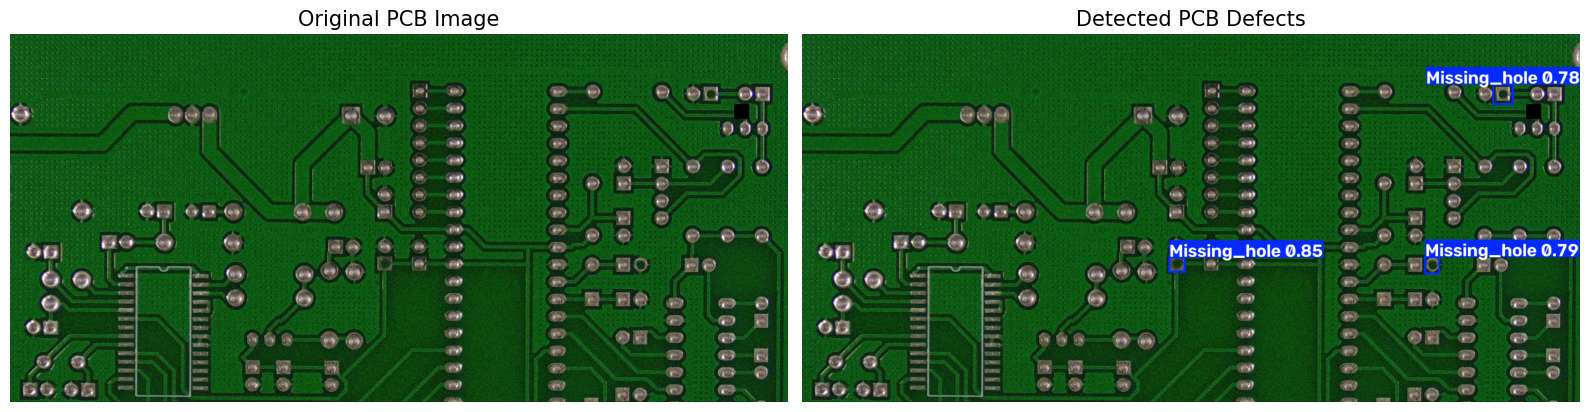

In [45]:
from PIL import Image
import matplotlib.pyplot as plt

result = results[0]

# Original image
original = Image.open(TEST_IMAGE).convert("RGB")

# Detected image with bounding boxes
detected = result.plot()[:, :, ::-1]

plt.figure(figsize=(16,8))

plt.subplot(1,2,1)
plt.imshow(original)
plt.title("Original PCB Image", fontsize=15)
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(detected)
plt.title("Detected PCB Defects", fontsize=15)
plt.axis("off")

plt.tight_layout()
plt.show()

In [44]:
%matplotlib inline

Image 1: 04_missing_hole_19_1.jpg


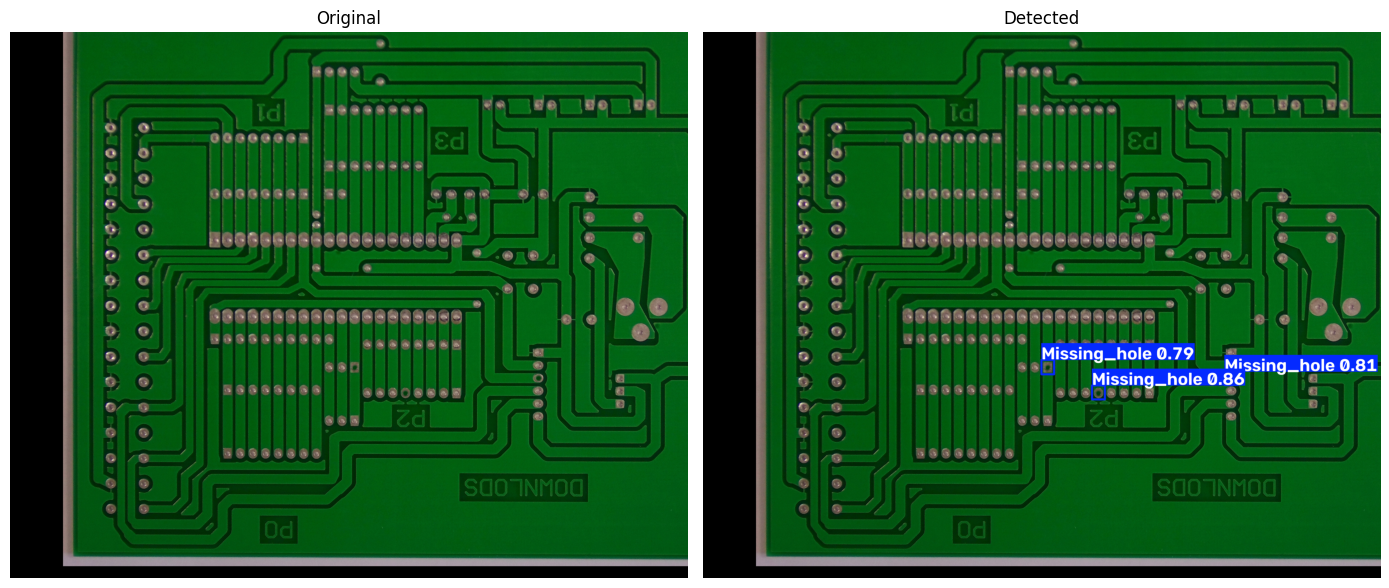

Detected Defects
Missing_hole        : 3
-----------------------------------
Total Defects      : 3
Inspection Status : FAILED ❌
Image 2: 01_spur_02_1.jpg


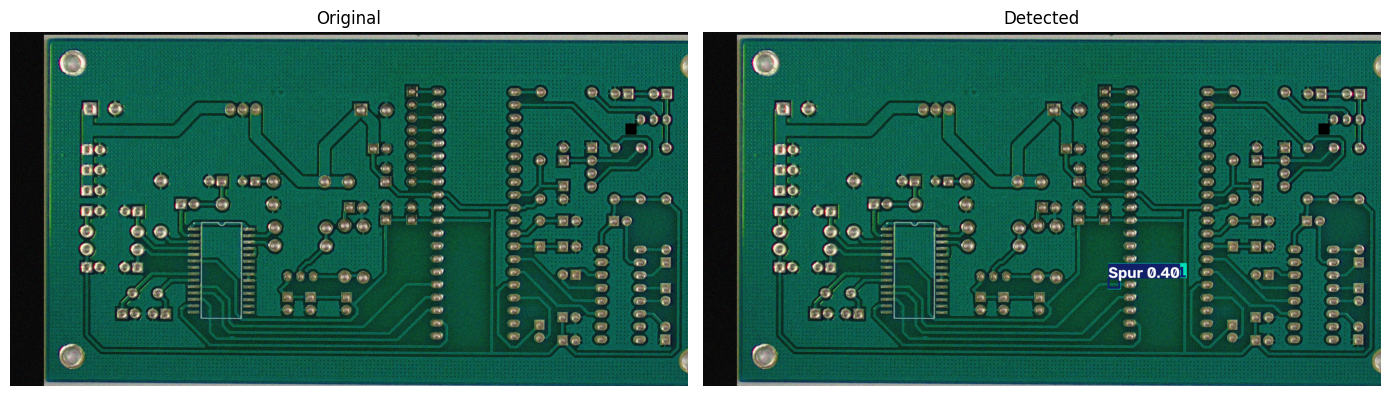

Detected Defects
Spur                : 1
Short               : 1
-----------------------------------
Total Defects      : 2
Inspection Status : FAILED ❌
Image 3: 01_mouse_bite_19_1.jpg


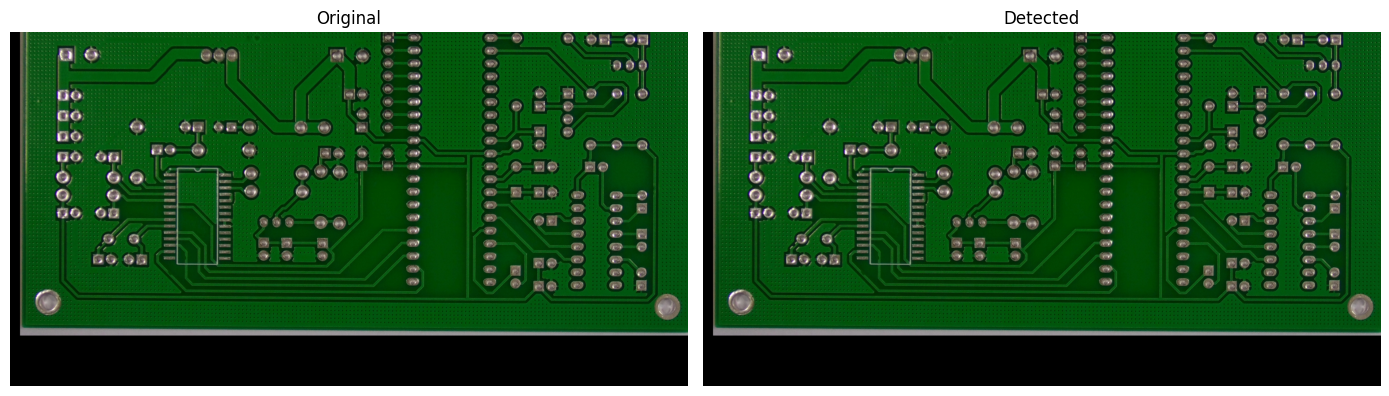

Detected Defects
No defects detected.
Inspection Status : PASSED ✅
Image 4: 04_spur_12_1.jpg


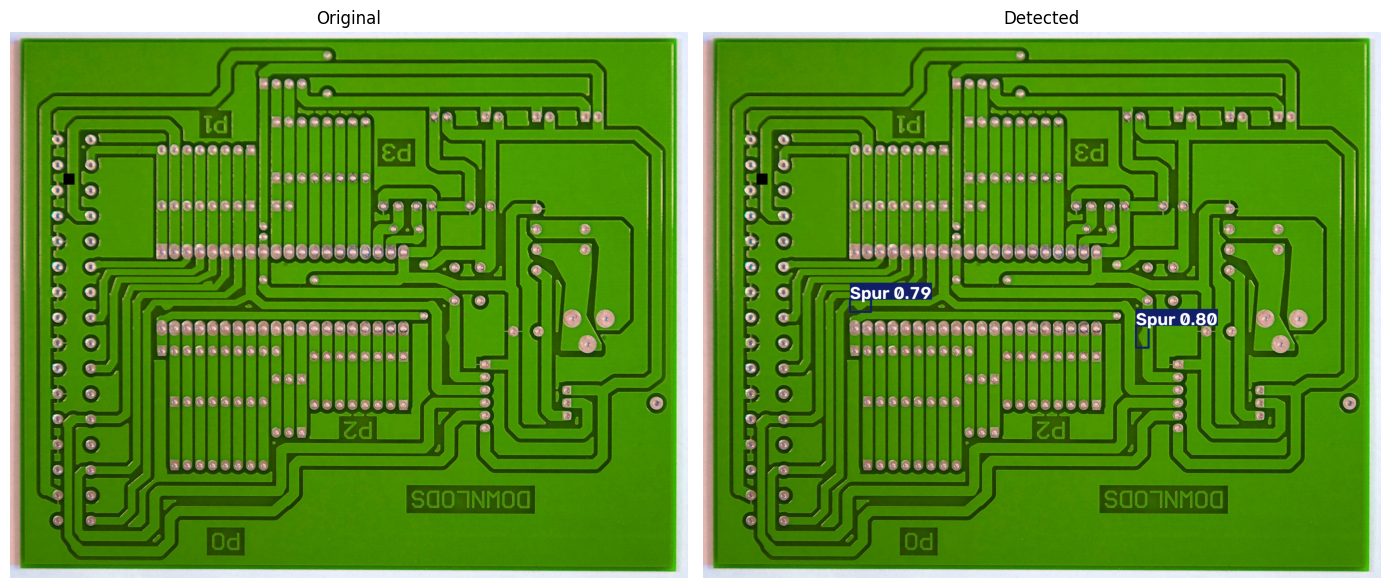

Detected Defects
Spur                : 2
-----------------------------------
Total Defects      : 2
Inspection Status : FAILED ❌
Image 5: 04_mouse_bite_08_1.jpg


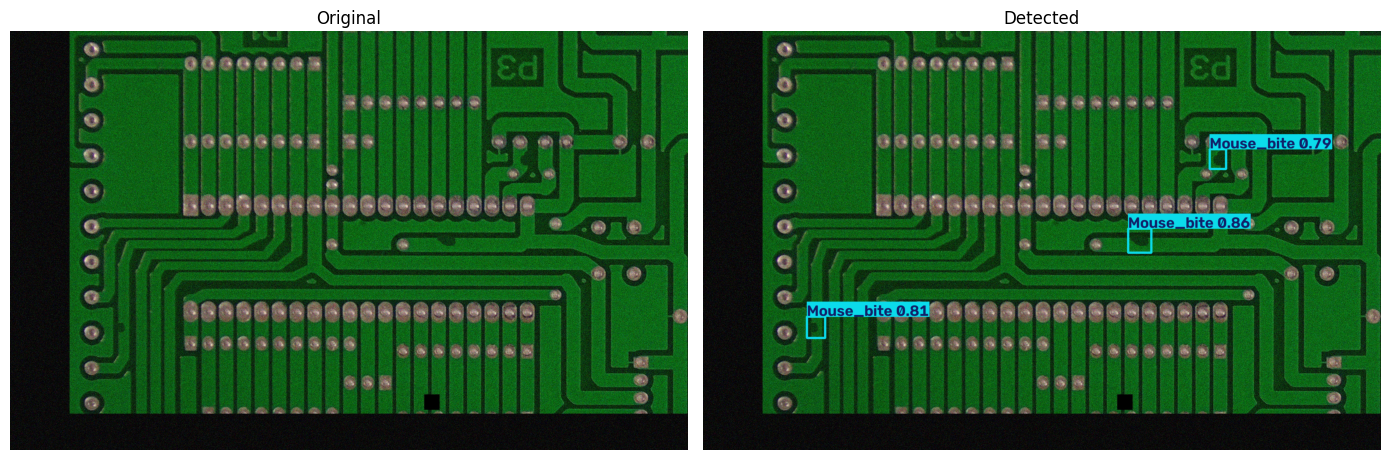

Detected Defects
Mouse_bite          : 3
-----------------------------------
Total Defects      : 3
Inspection Status : FAILED ❌


In [51]:
import random
from pathlib import Path
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt

# Test folder
TEST_FOLDER = (
    BASE_DIR
    / "extracted_dataset"
    / "PKU-Market-PCB(Data enhanced version)"
    / "test"
    / "images"
)

# Get all test images
all_images = list(TEST_FOLDER.glob("*.jpg"))

# Randomly choose 5 images
selected_images = random.sample(all_images, min(5, len(all_images)))

for idx, TEST_IMAGE in enumerate(selected_images, 1):

    print("="*70)
    print(f"Image {idx}: {TEST_IMAGE.name}")
    print("="*70)

    # Predict
    results = model.predict(
        source=str(TEST_IMAGE),
        imgsz=640,
        conf=0.25,
        verbose=False
    )

    result = results[0]

    counts = Counter()

    if result.boxes is not None and len(result.boxes) > 0:
        for cls in result.boxes.cls.cpu().numpy().astype(int):
            counts[result.names[cls]] += 1

    original = Image.open(TEST_IMAGE).convert("RGB")
    detected = result.plot()[:, :, ::-1]

    plt.figure(figsize=(14,6))

    plt.subplot(1,2,1)
    plt.imshow(original)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(detected)
    plt.title("Detected")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Detected Defects")

    if len(counts) == 0:
        print("No defects detected.")
        print("Inspection Status : PASSED ✅")
    else:
        total = 0
        for defect, cnt in counts.items():
            print(f"{defect:20}: {cnt}")
            total += cnt

        print("-"*35)
        print(f"Total Defects      : {total}")
        print("Inspection Status : FAILED ❌")

In [17]:
from ultralytics import YOLO

model = YOLO("training_runs/pku_yolov8n/weights/best.pt")

model.export(
    format="onnx",
    imgsz=640
)

print("ONNX model exported successfully!")

Ultralytics 8.4.75 🚀 Python-3.10.18 torch-2.5.1+cu121 CPU (Intel Xeon Gold 5118 CPU @ 2.30GHz)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from 'training_runs/pku_yolov8n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 10, 8400) (6.0 MB)

ONNX: starting export with onnx 1.19.1 opset 19...
ONNX: slimming with onnxslim 0.1.94...


2026-08-02 13:11:02.166683295 [W:onnxruntime:Default, device_discovery.cc:164 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:89 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


ONNX: export success ✅ 1.2s, saved as 'training_runs/pku_yolov8n/weights/best.onnx' (11.7 MB)

Export complete (1.5s)
Results saved to /home/jupyter-svecwai/Subbarao/anamoly_rv/training_runs/pku_yolov8n/weights/best.onnx
Predict:         yolo predict task=detect model=training_runs/pku_yolov8n/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=training_runs/pku_yolov8n/weights/best.onnx imgsz=640 data=/home/jupyter-svecwai/Subbarao/anamoly_rv/pku_data.yaml  
Visualize:       https://netron.app
ONNX model exported successfully!
